In [8]:
import pandas as pd

datos = pd.DataFrame({
    "bloques" : ["primero", "segundo", "tercero"],
    "valores" : [1,1,None]
})
print(datos["valores"].isna().sum,datos["valores"].duplicated().sum())
print(datos["bloques"].duplicated())

print(datos["bloques"].nunique())

<bound method Series.sum of 0    False
1    False
2     True
Name: valores, dtype: bool> 1
0    False
1    False
2    False
Name: bloques, dtype: bool
3


In [ ]:
from PIL import Image




In [ ]:

import pathlib as ptl
import pandas as pd

def cargar_datos_fichero(opcion,fichero):
    if ptl.Path(fichero).is_file():
        if (ptl.Path(fichero).suffix == ".csv") and (opcion == "1"):
            return pd.read_csv(fichero)
        elif (ptl.Path(fichero).suffix == ".json") and (opcion == "2"):
            return pd.read_json(fichero)
        else:
            print("La opción o extensión no se corresponde")
            return None
    else :
        print("No existe ese fichero")
        return None

opcion_elegida = input("Opciones de ficheros:\n\t1. CSV\n\t2. JSON\n\n\tOpción: ")
fichero=input("Fichero: ")
print(cargar_datos_fichero(opcion_elegida,fichero))

''

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar el dataset
df = pd.read_csv("sensores_industriales.csv")

# Mostrar las primeras filas para comprobar que se ha cargado correctamente
df.head()

'''## Ejercicio 1

Realiza lo siguiente:
- Muestra las cinco primeras filas
- Muestra las tres ultimas filas de datos
- ¿Cuál es la dimensión del dataset?
- Indica los nombres de las columnas del dataset.
- Indica cuántas filas y columnas tiene.

---
'''

# Mostrar las cinco primeras filas
print("Primeras cinco filas:")
display(df.head())

# Mostrar las tres últimas filas
print("Últimas tres filas:")
display(df.tail(3))

# Dimensiones del dataset
print("Dimensiones del dataset:", df.shape)

# Número de filas y columnas
filas, columnas = df.shape

print("Número de filas:", filas)
print("Número de columnas:", columnas)

# Nombres de las columnas
print("Nombres de las columnas:")
print(df.columns.tolist())


'''
## Ejercicio 2

Empecemos con la EDA. Realiza lo siguiente:
- Comprueba los tipos de datos del dataset
- ¿Hay valores ausentes por columna? Indica cuántas.
- Averigua cuántas filas completas estan duplicadas.

---
'''
# Comprobar los tipos de datos
print("Tipos de datos:")
print(df.dtypes)

# Comprobar los valores ausentes por columna
print("\nValores ausentes por columna:")
print(df.isnull().sum())

# Comprobar el número de filas duplicadas
print("\nNúmero de filas duplicadas:")
print(df.duplicated().sum())


'''## Ejercicio 3

Muestra los siguiente datos del dataset:
- El valor medio de consumo
- La temperatura mínima
- La humedad máxima
NOTA: todos los valores debes mostrarlos redondeados a dos decimales.

---'''

# Calcular los valores estadísticos
consumo_medio = df["consumo"].mean()
temperatura_minima = df["temperatura"].min()
humedad_maxima = df["humedad"].max()

# Mostrar los resultados redondeados
print("Consumo medio:", round(consumo_medio, 2))
print("Temperatura mínima:", round(temperatura_minima, 2))
print("Humedad máxima:", round(humedad_maxima, 2))


'''## Ejercicio 4

Realiza:
- Cuenta los registros de cada estado
- Enumera el número de registros de cada zona.
- ¿Cuántas zonas hay diferentes?
- ¿Cuántos sensores tienen un nombre diferente?

---'''

cuenta = df["estado"].value_counts()
print("Numero de registros por estado: \n", cuenta)

enumera = df["zona"].value_counts()
print("Numero de registros por zona: \n", enumera)

Nzonas = df["zona"].nunique()
print("Numero de zonas diferentes: ", Nzonas)

Nsensores = df["sensor"].nunique()
print("Numero de sensores con nombre diferente: ", Nsensores)


'''
## Ejercicio 5

Muestra las lecturas de senrores que estén en estado Alerta y cuya temperatura supere los 55 grados. Estos datos mostrados deben ser la fecha, el nombre del sensor, la temperatura y el consumo.
¿Cuántos registros hay en esa muestra?

---
'''
filtrado = df[(df["estado"] == "Alerta") & (df["temperatura"] > 55)][["fecha", "sensor", "temperatura", "consumo"]]
print("Registros filtrados:\n", filtrado)
print("Número de registros en la muestra:", filtrado.shape[0])



Primeras cinco filas:


,fecha,sensor,zona,turno,temperatura,humedad,consumo,vibración,presión,estado
0,2026-10-01 08:00,S01,Producción,Mañana,35.7,60.3,154.7,1.36,1.87,Normal
1,2026-10-01 09:00,S02,Almacén,Mañana,38.0,60.9,171.4,1.64,2.01,Normal
2,2026-10-01 10:00,S03,Laboratorio,Mañana,42.7,61.6,177.4,2.00,2.12,Normal
3,2026-10-01 11:00,S04,Producción,Mañana,43.6,52.0,193.8,2.29,2.24,Normal
4,2026-10-01 12:00,S05,Almacén,Mañana,45.7,59.3,201.9,2.25,2.35,Normal


Últimas tres filas:


,fecha,sensor,zona,turno,temperatura,humedad,consumo,vibración,presión,estado
117,2026-10-06 05:00,S10,Producción,Noche,55.1,53.3,211.2,2.68,2.32,Alerta
118,2026-10-01 15:00,S08,Almacén,Mañana,50.8,56.1,203.9,2.93,1.99,Normal
119,2026-10-03 08:00,S01,Producción,Mañana,38.8,59.3,165.1,1.24,1.87,Normal


Dimensiones del dataset: (120, 10)
Número de filas: 120
Número de columnas: 10
Nombres de las columnas:
['fecha', 'sensor', 'zona', 'turno', 'temperatura', 'humedad', 'consumo', 'vibración', 'presión', 'estado']
Tipos de datos:
fecha              str
sensor             str
zona               str
turno              str
temperatura    float64
humedad        float64
consumo        float64
vibración      float64
presión        float64
estado             str
dtype: object

Valores ausentes por columna:
fecha          0
sensor         0
zona           0
turno          0
temperatura    0
humedad        2
consumo        1
vibración      1
presión        0
estado         0
dtype: int64

Número de filas duplicadas:
2
Consumo medio: 193.45
Temperatura mínima: 35.2
Humedad máxima: 64.9
Numero de registros por estado: 
 estado
Normal    101
Alerta     19
Name: count, dtype: int64
Numero de registros por zona: 
 zona
Producción     41
Almacén        40
Laboratorio    39
Name: count, dtype: int64
Num

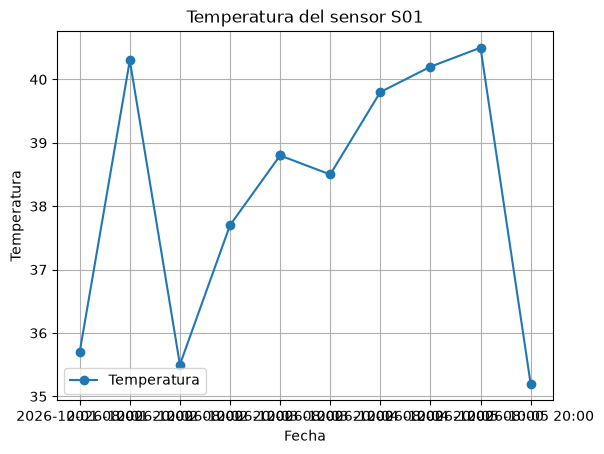

In [7]:
'''
## Ejercicio 6.

Representa la temperatura del sensor S01 durante sus lecturas, ordenadas por fecha. Incluye marcadores, título, etiquetas, cuadrícula y leyenda.

---
'''

df_s01 = df[df["sensor"] == "S01"]

df_s01 = df_s01.sort_values("fecha")

plt.plot(df_s01["fecha"], df_s01["temperatura"], marker="o", label="Temperatura")
plt.title("Temperatura del sensor S01")
plt.xlabel("Fecha")
plt.ylabel("Temperatura")
plt.grid(True)
plt.legend()
plt.show()


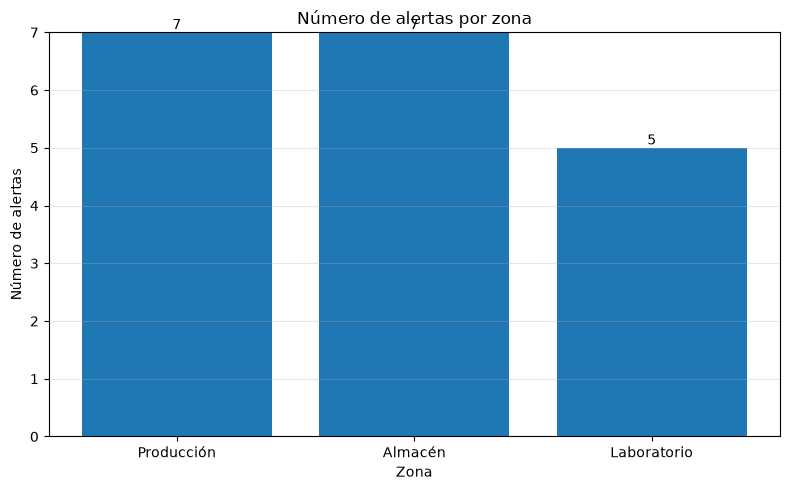

In [11]:
'''
## Ejercicio 7

Cuenta cuantas lecturas en estado Alerta hay por zona. Representa el resultado mediante barras con el valor encima de cada una de ellas, empleando las etiquetas de ejes y titulo. Asegúrate que se ven bien los valores representados y en caso contrario usa xlim() o ylim().

---
'''

alertas_zona = df[df["estado"] == "Alerta"]

conteo_zonas = alertas_zona["zona"].value_counts()

plt.figure(figsize=(8, 5))

barras = plt.bar(conteo_zonas.index, conteo_zonas.values)

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        int(altura),
        ha="center",
        va="bottom"
    )

plt.title("Número de alertas por zona")
plt.xlabel("Zona")
plt.ylabel("Número de alertas")
plt.ylim(0, conteo_zonas.max())
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

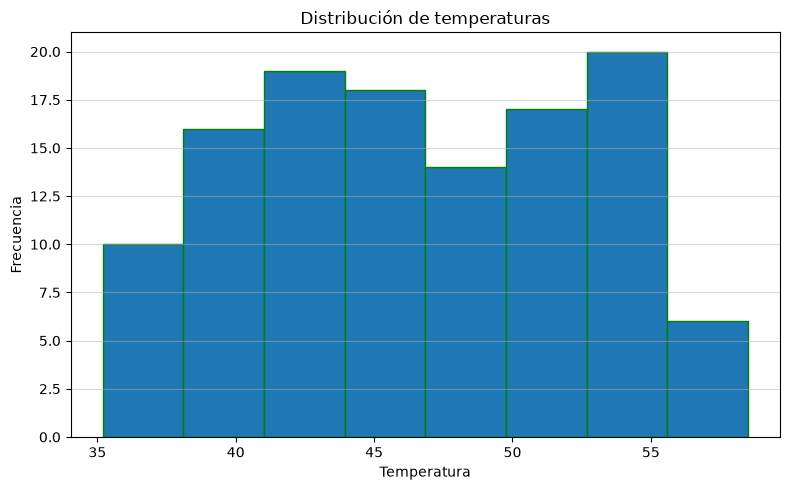

In [12]:
'''## Ejercicio 8

Construye un histograma de temperatura con 8 intervalos. Añade titulo, etiquetas y cuadricula horizontal (añade algo de transparencia).

---
'''

plt.figure(figsize=(8,5))

plt.hist(
    df["temperatura"].dropna(),
    bins = 8,
    edgecolor= "green"
)

plt.title("Distribución de temperaturas")
plt.xlabel("Temperatura")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.5)
plt.tight_layout()
plt.show()

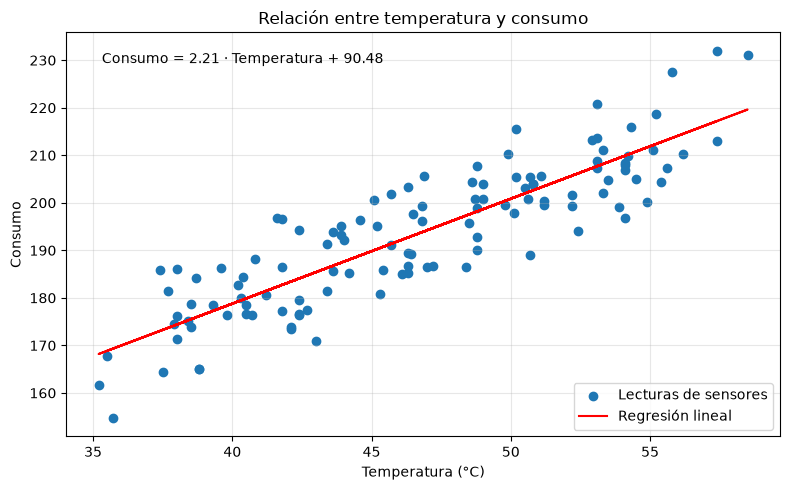

Ecuación de regresión: Consumo = 2.21 · Temperatura + 90.48
Consumo estimado para 50 °C: 200.86


In [14]:
''' 
## Ejercicio 9

Representa temperatura frente a consumo. Descarta aquellas filas que no tengan consumo o temperatura. Calcula una recta de regresion, dibújala y muestra su ecuación. Luego haz una estimación de cómo sería el consumo para una temperatura de 50 °C a partir de esa expresión matemática.

---

'''

datos = df.dropna(subset=["temperatura", "consumo"]).copy()
x = datos["temperatura"]
y = datos["consumo"]
pendiente, intercepto = np.polyfit(x, y, 1)


y_pred = pendiente * x + intercepto
plt.figure(figsize=(8, 5))
plt.scatter(x, y, label="Lecturas de sensores")
plt.plot(x, y_pred, color="red", label="Regresión lineal")
ecuacion = f"Consumo = {pendiente:.2f} · Temperatura + {intercepto:.2f}"

plt.title("Relación entre temperatura y consumo")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Consumo")
plt.legend()
plt.grid(alpha=0.3)

plt.text(
    0.05, 0.95,
    ecuacion,
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()
plt.show()

temperatura = 50
consumo_estimado = pendiente * temperatura + intercepto

print("Ecuación de regresión:", ecuacion)
print("Consumo estimado para 50 °C:", round(consumo_estimado, 2))

In [ ]:
'''## Ejercicio 10

Representa mediante un histograma la distribución de temperaturas registradas por los sensores. Añade un título, etiquetas de ejes, etc. y guarda el gráfico en formato png antes de mostrarlo.'''



# Crear el histograma
plt.figure(figsize=(8, 5))

plt.hist(
    df["Temperatura"].dropna(),
    bins=10,
    edgecolor="black"
)

# Añadir título y etiquetas
plt.title("Distribución de temperaturas de los sensores")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Frecuencia")

# Añadir cuadrícula horizontal
plt.grid(axis="y", alpha=0.3)

# Ajustar el gráfico
plt.tight_layout()

# Guardar el gráfico antes de mostrarlo
plt.savefig("histograma_temperaturas.png", dpi=300)

# Mostrar el gráfico
plt.show()